# Günlük Harcama Analizi ve Tahmini


**Colab'da nasıl çalıştırılır?**
1. `gunluk_harcama.csv` dosyasını hazır tutun.
2. Menüden **Çalışma zamanı → Tümünü çalıştır** deyin. Dosya bulunamazsa 4. hücre sizden yüklemenizi isteyecektir.
3. En alttaki **mini uygulama** hücresi sizden gün, öğün sayısı vb. bilgileri isteyip harcama tahmini verir.

> **Önemli not:** Bu projedeki veri seti, öğrenme amacıyla **sentetik olarak üretilmiştir** (`veri_uret.py`). Gerçek bir kişinin harcamaları değildir. Kendi harcama kaydınız varsa aynı sütun adlarıyla CSV'yi değiştirip bu defteri yeniden çalıştırabilirsiniz.

## 1️ - Proje Tanım Formu

| Alan | İçerik |
|---|---|
| **Proje adı** | Günlük Harcama Analizi ve Tahmini |
| **Problem cümlesi** | Bir günün özelliklerine (haftanın günü, dışarıda yenen öğün sayısı, ulaşım mesafesi, sosyal etkinlik, online alışveriş) bakarak o günkü **toplam harcamayı (TL) tahmin edebilir miyiz? Hangi özellik harcamayı en çok belirliyor?** |
| **Hedef değişken** | `gunluk_harcama_tl` (günlük toplam harcama, TL) |
| **Problem türü** | **Regresyon** (sayısal bir değer tahmin ediliyor) + **keşifsel veri analizi** |
| **Özellikler (girdiler)** | `haftanin_gunu`, `disarida_yemek`, `ulasim_km`, `sosyal_etkinlik`, `online_alisveris` |
| **Başarı ölçütü** | R² (açıklanan varyans) ve MAE (ortalama mutlak hata, TL) — test verisi üzerinde |

### Bu problem neden önemli?
Günlük harcamalar tek tek küçük görünür, ancak aylık bütçeyi belirleyen şey bu küçük kalemlerin toplamıdır. Hangi alışkanlıkların (dışarıda yemek, sosyal etkinlik, online alışveriş) ve hangi günlerin harcamayı yükselttiğini bilmek, bütçe planlamayı ve tasarruf kararlarını sezgiye değil veriye dayandırmayı sağlar.

## 2️ - Kütüphaneler ve Veriyi Yükleme

In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.rcParams["figure.dpi"] = 100          # grafik netliği
plt.rcParams["axes.grid"] = True          # arka plan ızgarası
plt.rcParams["grid.alpha"] = 0.3
print("Kütüphaneler hazır ✔")

Kütüphaneler hazır ✔


## İsterseniz veriyi aşağıdaki kodla üretebilir, ya da bu hücreyi atlayıp bir sonraki hücreyi çalıştırarak kendi verinizi yükleyebilirsiniz

In [21]:
# ⚙️ AYAR: Kendi verinizi kullanacaksanız False yapın
ORNEK_VERI_URET = True

def ornek_veri_uret(dosya="gunluk_harcama.csv"):
    rng = np.random.default_rng(42)          # sabit tohum: herkes aynı veriyi üretir
    n = 150                                  # 150 günlük kayıt

    tarih = pd.date_range("2026-03-02", periods=n, freq="D")
    gun_adlari = ["Pazartesi", "Salı", "Çarşamba", "Perşembe", "Cuma", "Cumartesi", "Pazar"]
    haftanin_gunu = [gun_adlari[d.dayofweek] for d in tarih]
    hafta_sonu = (tarih.dayofweek >= 5).astype(int)

    # --- Özellikler ---
    disarida_yemek = np.where(
        hafta_sonu == 1,
        rng.choice([0, 1, 2, 3], size=n, p=[0.05, 0.25, 0.40, 0.30]),
        rng.choice([0, 1, 2, 3], size=n, p=[0.20, 0.40, 0.30, 0.10]),
    )
    ulasim_km = np.where(
        hafta_sonu == 1,
        np.where(rng.random(n) < 0.30, 0.0, rng.uniform(2, 25, n)),
        rng.uniform(5, 30, n),
    ).round(1)
    sosyal = (rng.random(n) < np.where(hafta_sonu == 1, 0.60, 0.15)).astype(int)
    online = (rng.random(n) < 0.12).astype(int)

    # --- Hedef: günlük harcama (TL) ---
    harcama = (
        90 + 190 * disarida_yemek + 4.5 * ulasim_km + 320 * sosyal + 60 * hafta_sonu
        + online * (450 + rng.normal(0, 120, n))
        + rng.normal(0, 60, n)
    )
    harcama = np.clip(harcama, 40, None).round(0)

    df = pd.DataFrame({
        "tarih": tarih.strftime("%Y-%m-%d"),
        "haftanin_gunu": haftanin_gunu,
        "disarida_yemek": disarida_yemek,
        "ulasim_km": ulasim_km,
        "sosyal_etkinlik": np.where(sosyal == 1, "Var", "Yok"),
        "online_alisveris": np.where(online == 1, "Evet", "Hayır"),
        "gunluk_harcama_tl": harcama,
    })

    # --- Bilinçli 'kirli veri' (temizleme adımını göstermek için) ---
    # (eksik değerler, yazım tutarsızlıkları, hatalı giriş ve yinelenen satırlar)
    ...
    df.to_csv(dosya, index=False, encoding="utf-8-sig")
    print(f"✔ {dosya} oluşturuldu:", df.shape)

if ORNEK_VERI_URET:
    ornek_veri_uret()
else:
    print("Örnek veri üretilmedi; kendi gunluk_harcama.csv dosyanız kullanılacak.")

✔ gunluk_harcama.csv oluşturuldu: (150, 7)


In [22]:
DOSYA = "gunluk_harcama.csv"

# Dosya yoksa (Colab'da ilk çalıştırma) yükleme penceresi açılır
if not os.path.exists(DOSYA):
    try:
        from google.colab import files
        print("Lütfen gunluk_harcama.csv dosyasını seçin...")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"{DOSYA} bulunamadı. Dosyayı bu defterle aynı klasöre koyun.")

df = pd.read_csv(DOSYA, encoding="utf-8-sig")   # utf-8-sig: Excel'den gelen Türkçe karakterleri doğru okur
df.head(8)

,tarih,haftanin_gunu,disarida_yemek,ulasim_km,sosyal_etkinlik,online_alisveris,gunluk_harcama_tl
0,2026-03-02,Pazartesi,2,16.9,Yok,Hayır,494.0
1,2026-03-03,Salı,2,24.0,Yok,Hayır,725.0
2,2026-03-04,Çarşamba,0,27.6,Yok,Evet,739.0
3,2026-03-05,Perşembe,1,23.0,Yok,Hayır,359.0
4,2026-03-06,Cuma,0,29.1,Yok,Hayır,199.0
5,2026-03-07,Cumartesi,3,6.2,Var,Hayır,999.0
6,2026-03-08,Pazar,3,24.5,Var,Hayır,1036.0
7,2026-03-09,Pazartesi,2,7.9,Yok,Evet,998.0


## 3️ - Veri Sözlüğü

| Sütun | Tip | Rol | Anlamı |
|---|---|---|---|
| `tarih` | Tarih (YYYY-AA-GG) | Kimlik | Kaydın alındığı gün |
| `haftanin_gunu` | Kategorik | Özellik | Pazartesi … Pazar |
| `disarida_yemek` | Sayısal (tam sayı, 0–3) | Özellik | O gün dışarıda yenen öğün sayısı |
| `ulasim_km` | Sayısal (ondalık) | Özellik | O gün gidilen toplam yol (km) |
| `sosyal_etkinlik` | Kategorik (Var / Yok) | Özellik | O gün sinema, kafe, buluşma gibi bir etkinlik var mıydı? |
| `online_alisveris` | Kategorik (Evet / Hayır) | Özellik | O gün online alışveriş yapıldı mı? |
| `gunluk_harcama_tl` | Sayısal (TL) | **Hedef** | O günün toplam harcaması |

**Temizleme sırasında türetilen sütunlar** (modeller sayı ister, metin değil):

| Sütun | Tip | Anlamı |
|---|---|---|
| `hafta_sonu` | Sayısal (0/1) | Cumartesi veya Pazar ise 1 |
| `sosyal_var` | Sayısal (0/1) | `sosyal_etkinlik == "Var"` ise 1 |
| `online_var` | Sayısal (0/1) | `online_alisveris == "Evet"` ise 1 |

## 4️ - Ham Veriye İlk Bakış
Temizlemeye başlamadan önce veride neyin eksik veya tutarsız olduğuna bakılır

In [23]:
print("Ham veri boyutu (satır, sütun):", df.shape)
print("\nSütun tipleri ve dolu değer sayıları:")
df.info()
print("\nEksik değer sayısı:")
print(df.isna().sum())
print("\nYinelenen (birebir aynı) satır sayısı:", df.duplicated().sum())
print("\nsosyal_etkinlik değerleri :", df["sosyal_etkinlik"].unique().tolist())
print("online_alisveris değerleri:", df["online_alisveris"].unique().tolist())

Ham veri boyutu (satır, sütun): (150, 7)

Sütun tipleri ve dolu değer sayıları:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   tarih              150 non-null    object 
 1   haftanin_gunu      150 non-null    object 
 2   disarida_yemek     150 non-null    int64  
 3   ulasim_km          150 non-null    float64
 4   sosyal_etkinlik    150 non-null    object 
 5   online_alisveris   150 non-null    object 
 6   gunluk_harcama_tl  150 non-null    float64
dtypes: float64(2), int64(1), object(4)
memory usage: 8.3+ KB

Eksik değer sayısı:
tarih                0
haftanin_gunu        0
disarida_yemek       0
ulasim_km            0
sosyal_etkinlik      0
online_alisveris     0
gunluk_harcama_tl    0
dtype: int64

Yinelenen (birebir aynı) satır sayısı: 0

sosyal_etkinlik değerleri : ['Yok', 'Var']
online_alisveris değerleri: ['Hayır', 'Ev

## 5️ - Veri Temizleme

Ham veride şu sorunları buldum ve şöyle çözdüm:

1. **Yinelenen satırlar** → Aynı gün iki kez girilmiş kayıtlar silindi (aynı günü iki kez saymak modeli yanıltır).
2. **Yazım tutarsızlıkları** → `"var"`, `"YOK "`, `"EVET"`, `"hayır "` gibi değerler boşluk temizlenip baş harf büyütülerek standartlaştırıldı.
3. **Eksik değerler** → Hedef değişkeni (harcama) eksik olan satır silindi (tahmin edilecek şeyi bilmeden öğrenemeyiz). Eksik `ulasim_km` değerleri **medyan** ile dolduruldu (uç değerlerden etkilenmez).
4. **Aykırı değer** → IQR kuralıyla yüksek harcamalar bulundu ve  incelendi: Online alışveriş yapılan günlerdeki yüksek harcamalar gerçekçi, bu yüzden tutuldu. Ama hiç dışarıda yemek, sosyal etkinlik ve online alışveriş olmayan bir günde ~3.000 TL harcama görünüyor → büyük olasılıkla fazladan sıfır girilmiş bir **veri giriş hatası**, bu yüzden silindi.
5. **Sayısallaştırma** → Metin sütunlarından 0/1 değerli yeni sütunlar türetildi.

In [24]:
satir_once = len(df)

# 1) Yinelenen satırları sil
yinelenen = df.duplicated().sum()
df = df.drop_duplicates()
print(f"1) Silinen yinelenen satır: {yinelenen}")

# 2) Yazım tutarsızlıklarını düzelt (boşlukları at, ilk harfi büyüt)
for sutun in ["sosyal_etkinlik", "online_alisveris"]:
    df[sutun] = df[sutun].str.strip().str.capitalize()
print("2) Düzeltilmiş değerler:", df["sosyal_etkinlik"].unique().tolist(), df["online_alisveris"].unique().tolist())

# 3) Eksik değerler
hedef_eksik = df["gunluk_harcama_tl"].isna().sum()
df = df.dropna(subset=["gunluk_harcama_tl"])                 # hedefi eksik satırı sil
km_eksik = df["ulasim_km"].isna().sum()
df["ulasim_km"] = df["ulasim_km"].fillna(df["ulasim_km"].median())   # km eksiklerini medyanla doldur
print(f"3) Hedefi eksik silinen satır: {hedef_eksik} | Medyanla doldurulan km değeri: {km_eksik}")

# 4) Aykırı değer: IQR kuralı
Q1, Q3 = df["gunluk_harcama_tl"].quantile([0.25, 0.75])
ust_sinir = Q3 + 1.5 * (Q3 - Q1)
print(f"4) IQR üst sınırı: {ust_sinir:.0f} TL. Bu sınırı aşan günler:")
display(df[df["gunluk_harcama_tl"] > ust_sinir])

# Şüpheli olan: hiçbir 'pahalı' neden yokken çok yüksek harcama
supheli = (
    (df["disarida_yemek"] == 0) & (df["sosyal_etkinlik"] == "Yok")
    & (df["online_alisveris"] == "Hayır") & (df["gunluk_harcama_tl"] > ust_sinir)
)
print("   Veri giriş hatası şüphesiyle silinen satır:", supheli.sum())
df = df[~supheli].copy()

# 5) Modelin anlayacağı sayısal sütunları türet
df["tarih"] = pd.to_datetime(df["tarih"])
df["hafta_sonu"] = df["haftanin_gunu"].isin(["Cumartesi", "Pazar"]).astype(int)
df["sosyal_var"] = (df["sosyal_etkinlik"] == "Var").astype(int)
df["online_var"] = (df["online_alisveris"] == "Evet").astype(int)
df = df.reset_index(drop=True)

# Projede kullanacağımız sütun listeleri
HEDEF = "gunluk_harcama_tl"
OZELLIKLER = ["disarida_yemek", "ulasim_km", "sosyal_var", "online_var", "hafta_sonu"]
gun_sirasi = ["Pazartesi", "Salı", "Çarşamba", "Perşembe", "Cuma", "Cumartesi", "Pazar"]

print(f"\nSatır sayısı: {satir_once} → {len(df)}  |  Kalan eksik değer: {int(df.isna().sum().sum())}")

1) Silinen yinelenen satır: 0
2) Düzeltilmiş değerler: ['Yok', 'Var'] ['Hayır', 'Evet']
3) Hedefi eksik silinen satır: 0 | Medyanla doldurulan km değeri: 0
4) IQR üst sınırı: 1376 TL. Bu sınırı aşan günler:


,tarih,haftanin_gunu,disarida_yemek,ulasim_km,sosyal_etkinlik,online_alisveris,gunluk_harcama_tl
20,2026-03-22,Pazar,3,11.3,Var,Evet,1458.0
118,2026-06-28,Pazar,2,0.0,Var,Evet,1514.0


   Veri giriş hatası şüphesiyle silinen satır: 0

Satır sayısı: 150 → 150  |  Kalan eksik değer: 0


## 6️ - Özet İstatistikler (shape, describe, groupby)

In [25]:
print("Temiz veri boyutu (shape):", df.shape)
print("\n▶ describe(): sayısal sütunların özeti")
display(df[["disarida_yemek", "ulasim_km", HEDEF]].describe().round(1))

Temiz veri boyutu (shape): (150, 10)

▶ describe(): sayısal sütunların özeti


,disarida_yemek,ulasim_km,gunluk_harcama_tl
count,150.0,150.0,150.0
mean,1.4,15.5,562.5
std,1.0,8.4,300.2
min,0.0,0.0,40.0
25%,1.0,8.9,310.0
50%,1.5,15.8,538.5
75%,2.0,22.9,736.2
max,3.0,30.0,1514.0


In [26]:
print("▶ groupby: haftanın gününe göre harcama (TL)")
display(df.groupby("haftanin_gunu")[HEDEF].agg(["mean", "median", "count"]).reindex(gun_sirasi).round(0))

print("▶ groupby: dışarıda yenen öğün sayısına göre ortalama harcama (TL)")
display(df.groupby("disarida_yemek")[HEDEF].mean().round(0).to_frame("ort_harcama_tl"))

print("▶ groupby: sosyal etkinlik ve online alışverişe göre ortalama harcama (TL)")
display(df.groupby("sosyal_etkinlik")[HEDEF].mean().round(0).to_frame("ort_harcama_tl"))
display(df.groupby("online_alisveris")[HEDEF].agg(["mean", "count"]).round(0))

▶ groupby: haftanın gününe göre harcama (TL)


,mean,median,count
haftanin_gunu,,,
Pazartesi,478.0,493.0,22
Salı,509.0,514.0,22
Çarşamba,589.0,538.0,22
Perşembe,406.0,293.0,21
Cuma,436.0,360.0,21
Cumartesi,729.0,737.0,21
Pazar,795.0,708.0,21


▶ groupby: dışarıda yenen öğün sayısına göre ortalama harcama (TL)


,ort_harcama_tl
disarida_yemek,
0,237.0
1,443.0
2,709.0
3,939.0


▶ groupby: sosyal etkinlik ve online alışverişe göre ortalama harcama (TL)


,ort_harcama_tl
sosyal_etkinlik,
Var,856.0
Yok,456.0


,mean,count
online_alisveris,,
Evet,952.0,13
Hayır,526.0,137


In [27]:
print("▶ Her özelliğin hedefle korelasyonu (−1 ile +1 arası; 0 = doğrusal ilişki yok)")
display(df[OZELLIKLER + [HEDEF]].corr()[HEDEF].drop(HEDEF).round(2).to_frame("korelasyon"))

▶ Her özelliğin hedefle korelasyonu (−1 ile +1 arası; 0 = doğrusal ilişki yok)


,korelasyon
disarida_yemek,0.77
ulasim_km,-0.02
sosyal_var,0.59
online_var,0.40
hafta_sonu,0.42


## 7️ - Görselleştirme

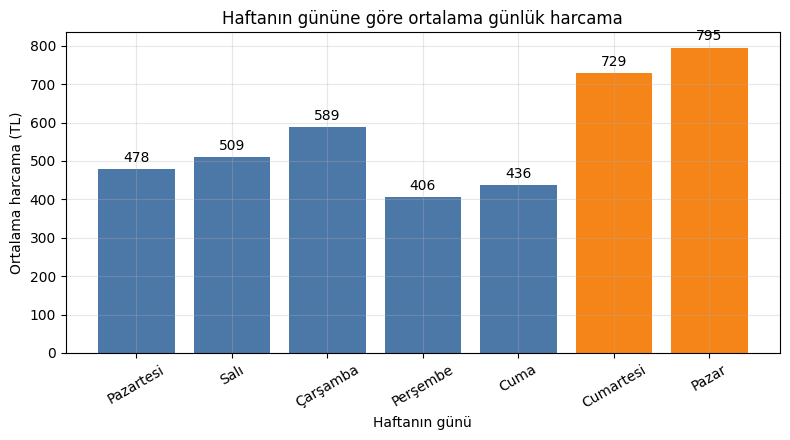

In [28]:
# Grafik 1: Haftanın gününe göre ortalama harcama
ort = df.groupby("haftanin_gunu")[HEDEF].mean().reindex(gun_sirasi)
renkler = ["#4C78A8"] * 5 + ["#F58518"] * 2          # hafta içi mavi, hafta sonu turuncu

fig, ax = plt.subplots(figsize=(8, 4.5))
cubuklar = ax.bar(ort.index, ort.values, color=renkler)
ax.bar_label(cubuklar, fmt="%.0f", padding=3)
ax.set_title("Haftanın gününe göre ortalama günlük harcama")
ax.set_xlabel("Haftanın günü")
ax.set_ylabel("Ortalama harcama (TL)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("grafik1_gunlere_gore.png", dpi=150)
plt.show()

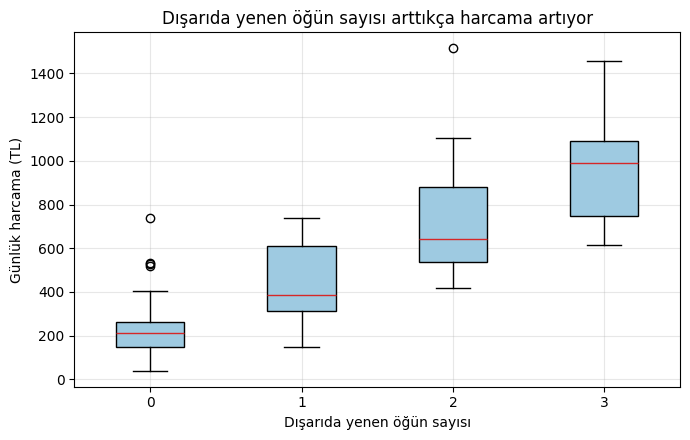

In [29]:
# Grafik 2: Dışarıda yenen öğün sayısına göre harcama dağılımı (kutu grafiği)
ogun_degerleri = sorted(df["disarida_yemek"].unique())
gruplar = [df.loc[df["disarida_yemek"] == k, HEDEF] for k in ogun_degerleri]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(gruplar, patch_artist=True, boxprops=dict(facecolor="#9ecae1"), medianprops=dict(color="#d62728"))
ax.set_xticks(range(1, len(ogun_degerleri) + 1))
ax.set_xticklabels(ogun_degerleri)
ax.set_title("Dışarıda yenen öğün sayısı arttıkça harcama artıyor")
ax.set_xlabel("Dışarıda yenen öğün sayısı")
ax.set_ylabel("Günlük harcama (TL)")
plt.tight_layout()
plt.savefig("grafik2_ogun_harcama.png", dpi=150)
plt.show()

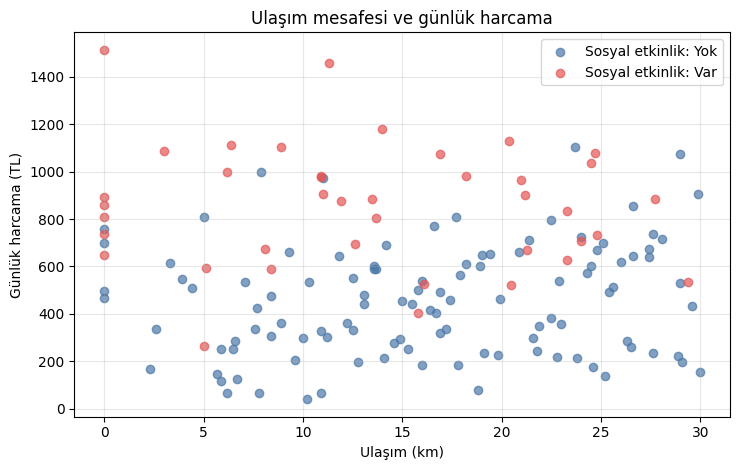

In [30]:
# Grafik 3: Ulaşım mesafesi ve harcama (renk = sosyal etkinlik var mı?)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for deger, renk in [("Yok", "#4C78A8"), ("Var", "#E45756")]:
    alt = df[df["sosyal_etkinlik"] == deger]
    ax.scatter(alt["ulasim_km"], alt[HEDEF], color=renk, alpha=0.7, label=f"Sosyal etkinlik: {deger}")
ax.set_title("Ulaşım mesafesi ve günlük harcama")
ax.set_xlabel("Ulaşım (km)")
ax.set_ylabel("Günlük harcama (TL)")
ax.legend()
plt.tight_layout()
plt.savefig("grafik3_km_harcama.png", dpi=150)
plt.show()

## 8️ - Keşif Bulguları — Hangi özellik belirleyici?

1. **Dışarıda yemek en güçlü belirleyici.** Hedefle korelasyonu ≈ **0,77** (en yüksek). Hiç dışarıda yemeyen günlerde ortalama ≈ 235 TL iken 3 öğün dışarıda yenen günlerde ≈ 939 TL — her ek öğün kabaca +190.4 TL.
2. **Sosyal etkinlik harcamayı belirgin şekilde artırıyor.** Etkinlik olan günlerin ortalaması ≈ 856 TL, olmayanların ≈ 459 TL (yaklaşık 400 TL fark).
3. **Online alışveriş nadir ama pahalı.** Online alışveriş yapılan günlerin ortalaması ≈ 952 TL, yapılmayanların ≈ 526 TL. Model de bunu doğruluyor: tek bir kalem olarak en büyük etki (≈ +384.4 TL).
4. **Hafta sonu daha pahalı, ama sebebi "hafta sonu olması" değil.** Cumartesi (≈ 729 TL) ve Pazar (≈ 795 TL), hafta içinden (≈ 406–589 TL) pahalı; fakat hafta sonları daha çok dışarıda yeniyor ve daha çok sosyal etkinlik oluyor. Diğer özellikler sabitlenince hafta sonunun kendi etkisi yalnızca ≈ +61.3 TL.
5. **Ulaşım mesafesinin tek başına korelasyonu ≈ 0** (−0,01) çıkıyor, ama model her km için ≈ +5.1 TL ekliyor. Muhtemel sebep: hafta sonları az yol gidilip çok harcanıyor, bu da etkiyi maskeliyor. **Ders:** Tek bir korelasyon rakamına bakıp bir özelliği çöpe atmayın.

## 9️ - Model Eğitimi

### Model seçim gerekçesi
Hedef değişken sürekli bir sayı (TL) olduğu için **regresyon** modeli gerekiyor. **Doğrusal Regresyon** seçtim çünkü veri küçük (~150 satır), etkiler yaklaşık toplamsal (her öğün veya etkinlik harcamaya bir miktar ekliyor) ve katsayıları "her öğün +190.4 TL" gibi doğrudan yorumlanabiliyor. Karşılaştırma için daha karmaşık bir **Random Forest** de eğittim; küçük veride eğitimi ezberleyip testte geriledi (aşırı öğrenme işareti), bu yüzden basit modelle devam ettim.

### Eğitim / test bölünmesi
Modelin başarısını dürüstçe ölçmek için verinin %80'i ile eğitiyor, hiç görmediği %20'si ile test ediyoruz.

In [31]:
X = df[OZELLIKLER]     # girdiler
y = df[HEDEF]          # tahmin edilecek değer

X_egitim, X_test, y_egitim, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Tüm veri         :", X.shape)
print("Eğitim  (X, y)   :", X_egitim.shape, y_egitim.shape)
print("Test    (X, y)   :", X_test.shape, y_test.shape)

Tüm veri         : (150, 5)
Eğitim  (X, y)   : (120, 5) (120,)
Test    (X, y)   : (30, 5) (30,)


In [32]:
model = LinearRegression()
model.fit(X_egitim, y_egitim)        # ◀ MODEL EĞİTİMİ: model burada örneklerden öğreniyor

print(f"Taban harcama (sabit terim): {model.intercept_:.1f} TL\n")
print("Modelin öğrendiği etkiler (diğerleri sabitken):")
for ozellik, katsayi in zip(OZELLIKLER, model.coef_):
    print(f"  {ozellik:15s}: {katsayi:+7.1f} TL")

Taban harcama (sabit terim): 77.7 TL

Modelin öğrendiği etkiler (diğerleri sabitken):
  disarida_yemek :  +190.4 TL
  ulasim_km      :    +5.1 TL
  sosyal_var     :  +313.3 TL
  online_var     :  +384.4 TL
  hafta_sonu     :   +61.3 TL


## 10 - Başarı Ölçümü

In [33]:
tahmin_test = model.predict(X_test)

r2_egitim = model.score(X_egitim, y_egitim)           # eğitim R²
r2_test = r2_score(y_test, tahmin_test)               # test R²
mae = mean_absolute_error(y_test, tahmin_test)        # ortalama mutlak hata (TL)
rmse = np.sqrt(mean_squared_error(y_test, tahmin_test))

print(f"Eğitim R² : {r2_egitim:.3f}")
print(f"Test R²   : {r2_test:.3f}   ← başarı puanı (≈ %{r2_test*100:.0f} açıklanan varyans)")
print(f"Test MAE  : {mae:.1f} TL   (ortalama harcamanın %{mae / y.mean() * 100:.0f}'u)")
print(f"Test RMSE : {rmse:.1f} TL")

Eğitim R² : 0.946
Test R²   : 0.933   ← başarı puanı (≈ %93 açıklanan varyans)
Test MAE  : 60.6 TL   (ortalama harcamanın %11'u)
Test RMSE : 84.0 TL


In [34]:
# Karşılaştırma 1: "Hep ortalamayı tahmin et" (en basit referans)
taban = DummyRegressor(strategy="mean").fit(X_egitim, y_egitim)
# Karşılaştırma 2: Daha karmaşık model (Random Forest)
rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_egitim, y_egitim)

sonuc = pd.DataFrame({
    "Model": ["Hep ortalamayı tahmin et", "Doğrusal Regresyon (seçilen)", "Random Forest"],
    "Eğitim R²": [taban.score(X_egitim, y_egitim), model.score(X_egitim, y_egitim), rf.score(X_egitim, y_egitim)],
    "Test R²": [r2_score(y_test, taban.predict(X_test)), r2_test, r2_score(y_test, rf.predict(X_test))],
    "Test MAE (TL)": [mean_absolute_error(y_test, taban.predict(X_test)), mae, mean_absolute_error(y_test, rf.predict(X_test))],
}).round(3)
display(sonuc)

# Çapraz doğrulama: veriyi 5 farklı şekilde bölüp test et (tek bir bölünmeye güvenmemek için)
cv = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print("5-katlı çapraz doğrulama R² değerleri:", cv.round(3))
print(f"Ortalama: {cv.mean():.3f}  (en düşük {cv.min():.3f}, en yüksek {cv.max():.3f})")

,Model,Eğitim R²,Test R²,Test MAE (TL)
0,Hep ortalamayı tahmin et,0.000,-0.025,258.900
1,Doğrusal Regresyon (seçilen),0.946,0.933,60.567
2,Random Forest,0.984,0.891,70.736


5-katlı çapraz doğrulama R² değerleri: [0.935 0.926 0.934 0.933 0.916]
Ortalama: 0.929  (en düşük 0.916, en yüksek 0.935)


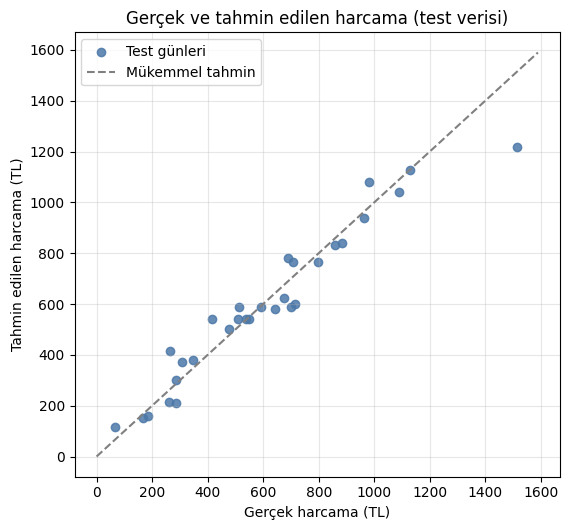

In [39]:
# Grafik 4: Gerçek vs tahmin (nokta çizgiye ne kadar yakınsa tahmin o kadar iyi)
fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.scatter(y_test, tahmin_test, color="#4C78A8", alpha=0.85, label="Test günleri")
sinir = [0, max(y_test.max(), tahmin_test.max()) * 1.05]
ax.plot(sinir, sinir, "--", color="gray", label="Mükemmel tahmin")
ax.set_title("Gerçek ve tahmin edilen harcama (test verisi)")
ax.set_xlabel("Gerçek harcama (TL)")
ax.set_ylabel("Tahmin edilen harcama (TL)")
ax.legend()
plt.tight_layout()
plt.savefig("grafik4_gercek_tahmin.png", dpi=150)
plt.show()

### Başarı puanının yorumu
> **Not:** "Doğruluk (accuracy)" sınıflandırma problemlerinin ölçütüdür. Regresyonda bunun karşılığı **R²**'dir: model, harcamadaki değişimin yüzde kaçını açıklıyor?

* **Test R² ≈ 0,933:** Model, günler arası harcama farkının yaklaşık %93.3'ünü açıklıyor. "Hep ortalamayı tahmin et" referansı ise R² ≈ −0,025 ile hiçbir şey açıklayamıyor — yani model gerçekten bir şey öğrenmiş.
* **MAE ≈ 60.6 TL:** Tahminler ortalama olarak gerçek değerden yaklaşık 60.6 TL sapıyor; bu, ortalama günlük harcamanın (~564 TL) kabaca %11'i. Referans modelde bu hata ≈ 258.9 TL.

## 1️1️ - Yeni Örnekler İçin Tahmin Tablosu (Girdi → Tahmin)
Modelin hiç görmediği, elle yazdığım 4 yeni gün:

In [36]:
HAFTA_SONU = ["Cumartesi", "Pazar"]

def girdi_hazirla(gun, yemek, km, sosyal, online):
    """Kullanıcının girdilerini modelin beklediği sütun düzenine çevirir."""
    satir = {
        "disarida_yemek": yemek,
        "ulasim_km": km,
        "sosyal_var": int(sosyal == "Var"),
        "online_var": int(online == "Evet"),
        "hafta_sonu": int(gun in HAFTA_SONU),
    }
    return pd.DataFrame([satir], columns=OZELLIKLER)

yeni_gunler = [
    # (gün, dışarıda öğün, km, sosyal etkinlik, online alışveriş)
    ("Salı",      0,  5, "Yok", "Hayır"),   # evde geçen sakin bir gün
    ("Perşembe",  2, 18, "Yok", "Hayır"),   # sıradan bir iş günü
    ("Cumartesi", 3, 12, "Var", "Hayır"),   # arkadaşlarla uzun bir gün
    ("Pazartesi", 1, 25, "Yok", "Evet"),    # online sipariş verilen gün
]

satirlar = []
for gun, yemek, km, sosyal, online in yeni_gunler:
    tahmin = model.predict(girdi_hazirla(gun, yemek, km, sosyal, online))[0]
    satirlar.append({"Gün": gun, "Dışarıda öğün": yemek, "Ulaşım (km)": km,
                     "Sosyal etkinlik": sosyal, "Online alışveriş": online,
                     "→ Tahmin (TL)": round(tahmin)})
display(pd.DataFrame(satirlar))

,Gün,Dışarıda öğün,Ulaşım (km),Sosyal etkinlik,Online alışveriş,→ Tahmin (TL)
0,Salı,0,5,Yok,Hayır,103
1,Perşembe,2,18,Yok,Hayır,551
2,Cumartesi,3,12,Var,Hayır,1085
3,Pazartesi,1,25,Yok,Evet,780


## 1️2️ - Değerlendirme Notu — Model güvenilir mi?

**Kısaca: Bu veri için makul ölçüde güvenilir; ama gerçek hayata birebir taşınamaz.**

**Güvenilir saydıran işaretler**
* **Aşırı öğrenme belirtisi yok:** Eğitim R² (≈ 0,946) ile test R² (≈ 0,933) birbirine çok yakın. Model eğitim verisini ezberlememiş, görmediği günlerde de başarılı.
* **Sonuç şansa bağlı değil:** 5-katlı çapraz doğrulamada R² değerleri 0,91–0,94 arasında kaldı (ortalama ≈ 0,929).
* **Karşılaştırma bunu destekliyor:** Daha karmaşık Random Forest eğitimde 0,984 alıp testte ≈ 0,891'e düştü çünkü aşırı öğrenme oldu. Basit model daha tutarlı.

**Dikkat edilmesi gerekenler (sınırlılıklar)**
* **Veri küçük:** Test kümesi yalnızca 30 gün; puan, bölünmeye göre biraz oynayabilir.
* **Veri simüle:** İlişkileri biz kurguladığımız için gerçek hayatta puan **daha düşük** olur (kira, fatura, maaş günü, sürpriz giderler gibi görmediğimiz etkenler gürültü yaratır).
* **Doğrusal varsayım:** Model etkileri toplar; "hafta sonu + sosyal etkinlik birlikte" gibi karşılıklı etkileri yakalamaz.
* **Eğitim aralığı dışında güvenilmez:** Eğitimde 3 öğün ve ≈ 30 km'ye kadar günler vardı; 6 öğün veya 100 km gibi girdilerde tahmine güvenmeyin.

## 1️3️ - Mini Uygulama: Girdi → Tahmin → Anlamlı Çıktı
Aşağıdaki fonksiyon bir günün bilgilerini alır; **tahmini harcamayı, olası aralığı, harcama seviyesini ve en büyük harcama kalemini** söyler.

In [37]:
ETIKET = {"disarida_yemek": "dışarıda yemek", "ulasim_km": "ulaşım", "sosyal_var": "sosyal etkinlik",
          "online_var": "online alışveriş", "hafta_sonu": "hafta sonu"}

def tl(x):
    """1234.5 → '1.235 TL' biçimi"""
    return f"{x:,.0f}".replace(",", ".") + " TL"

def harcama_tahmin_et(gun, yemek, km, sosyal, online):
    girdi = girdi_hazirla(gun, yemek, km, sosyal, online)
    tahmin = max(float(model.predict(girdi)[0]), 0)          # harcama negatif olamaz

    alt, ust = max(tahmin - rmse, 0), tahmin + rmse           # ± 1 RMSE ≈ olası aralık
    yuzde = (df[HEDEF] < tahmin).mean() * 100                 # geçmiş günlerin yüzde kaçından pahalı?
    seviye = "Düşük" if yuzde < 33 else "Orta" if yuzde < 66 else "Yüksek"

    katkilar = pd.Series(model.coef_ * girdi.iloc[0].values, index=OZELLIKLER)
    if katkilar.max() > 0:
        en_buyuk = katkilar.idxmax()
        yorum = f"En büyük kalem: {ETIKET[en_buyuk]} (≈ {tl(katkilar[en_buyuk])})."
    else:
        yorum = "Belirgin bir harcama kalemi yok; sakin bir gün."

    print("-" * 70)
    print(f"Girdi          : {gun} | {yemek} öğün dışarıda | {km:g} km | Sosyal etkinlik: {sosyal} | Online alışveriş: {online}")
    print(f"Tahmin         : {tl(tahmin)}  (olası aralık ≈ {tl(alt)} – {tl(ust)})")
    print(f"Seviye         : {seviye}  (geçmiş günlerin %{yuzde:.0f}'inden daha pahalı)")
    print(f"Yorum          : {yorum}")
    if km > df["ulasim_km"].max() or yemek > df["disarida_yemek"].max():
        print("Uyarı          : Girdi, modelin eğitildiği aralığın dışında; tahmine temkinli yaklaşın.")
    print("-" * 70)
    return tahmin

# Hızlı deneme
harcama_tahmin_et("Cumartesi", 3, 12, "Var", "Hayır")
harcama_tahmin_et("Salı", 0, 5, "Yok", "Hayır")

----------------------------------------------------------------------
Girdi          : Cumartesi | 3 öğün dışarıda | 12 km | Sosyal etkinlik: Var | Online alışveriş: Hayır
Tahmin         : 1.085 TL  (olası aralık ≈ 1.001 TL – 1.169 TL)
Seviye         : Yüksek  (geçmiş günlerin %95'inden daha pahalı)
Yorum          : En büyük kalem: dışarıda yemek (≈ 571 TL).
----------------------------------------------------------------------
----------------------------------------------------------------------
Girdi          : Salı | 0 öğün dışarıda | 5 km | Sosyal etkinlik: Yok | Online alışveriş: Hayır
Tahmin         : 103 TL  (olası aralık ≈ 19 TL – 187 TL)
Seviye         : Düşük  (geçmiş günlerin %3'inden daha pahalı)
Yorum          : En büyük kalem: ulaşım (≈ 26 TL).
----------------------------------------------------------------------


103.24107316496305

### Etkileşimli sürüm
Aşağıdaki hücreyi çalıştırınca uygulama sizden gün, öğün sayısı, km, sosyal etkinlik ve online alışveriş bilgisini ister. Çıkmak için gün sorusuna `q` yazın.

In [38]:
def sade(metin):
    """Türkçe karakterleri sadeleştirir: 'Çarşamba' ve 'carsamba' aynı sayılır."""
    return metin.strip().lower().translate(str.maketrans("çğıöşü", "cgiosu"))

GUNLER = {sade(g): g for g in gun_sirasi}

def sayi_al(soru, alt, ust, tur=float):
    while True:
        try:
            deger = tur(input(soru).replace(",", "."))
            if alt <= deger <= ust:
                return deger
        except ValueError:
            pass
        print(f"  ✗ Lütfen {alt} ile {ust} arasında bir sayı girin.")

def evet_hayir(soru, evet_degeri, hayir_degeri):
    while True:
        cevap = sade(input(soru))
        if cevap in ("e", "evet", "var"):
            return evet_degeri
        if cevap in ("h", "hayir", "yok"):
            return hayir_degeri
        print("  ✗ Lütfen e (evet) veya h (hayır) yazın.")

def uygulama():
    print("=== Günlük Harcama Tahmin Uygulaması (çıkmak için 'q') ===")
    while True:
        gun = sade(input("\nHaftanın günü (ör. Cumartesi): "))
        if gun in ("q", "cikis"):
            print("Görüşmek üzere!")
            break
        if gun not in GUNLER:
            print("  ✗ Gün anlaşılamadı. Örnek: Pazartesi, Salı, Çarşamba ...")
            continue
        yemek = sayi_al("Dışarıda kaç öğün yediniz? (0-3): ", 0, 3, int)
        km = sayi_al("Kaç km yol gittiniz? (0-60): ", 0, 60, float)
        sosyal = evet_hayir("Sosyal etkinlik var mıydı? (e/h): ", "Var", "Yok")
        online = evet_hayir("Online alışveriş yaptınız mı? (e/h): ", "Evet", "Hayır")
        harcama_tahmin_et(GUNLER[gun], yemek, km, sosyal, online)

uygulama()

=== Günlük Harcama Tahmin Uygulaması (çıkmak için 'q') ===

Haftanın günü (ör. Cumartesi): Salı
Dışarıda kaç öğün yediniz? (0-3): 1
Kaç km yol gittiniz? (0-60): 31
Sosyal etkinlik var mıydı? (e/h): h
Online alışveriş yaptınız mı? (e/h): e
----------------------------------------------------------------------
Girdi          : Salı | 1 öğün dışarıda | 31 km | Sosyal etkinlik: Yok | Online alışveriş: Evet
Tahmin         : 811 TL  (olası aralık ≈ 727 TL – 895 TL)
Seviye         : Yüksek  (geçmiş günlerin %81'inden daha pahalı)
Yorum          : En büyük kalem: online alışveriş (≈ 384 TL).
Uyarı          : Girdi, modelin eğitildiği aralığın dışında; tahmine temkinli yaklaşın.
----------------------------------------------------------------------

Haftanın günü (ör. Cumartesi): q
Görüşmek üzere!


## 1️4️ - Sonuç ve Çıkarımlar
* **Problem:** Günün özelliklerinden günlük harcamayı tahmin etmek.
* **Veri:** 150 günlük simüle kayıt → temizleme sonrası 150 gün, 5 özellik.
* **Model:** Doğrusal Regresyon — test R² ≈ 0,933, ortalama hata (MAE) ≈ 60.6 TL.
* **Çıkarım:** Harcamayı en çok **dışarıda yemek, sosyal etkinlik ve online alışveriş** belirliyor; hafta sonu etkisinin büyük kısmı aslında bu alışkanlıklardan geliyor. Bütçeyi azaltmak isteyen biri için en etkili kaldıraç "hafta sonu"nu değil bu üç alışkanlığı yönetmek.

### Sonraki adımlar (projeyi geliştirmek için)
1. Simüle veriyi **kendi gerçek harcama kaydınızla** değiştirin (30–60 gün bile yeterli).
2. Harcamayı kategorilere ayırın (yemek, ulaşım, eğlence) ve her biri için ayrı model deneyin.
3. Mini uygulamayı Streamlit ile web sayfasına dönüştürüp GitHub'da paylaşın.